# PathSnap — 01 · Dataset Exploration (EDA)

**Partitions used:** `train` (80 trips) and `student_test` (10 trips). The evaluator-testing partition is not available to us and is never touched.

Goals (from *Dataset Exploration* guide §4): inventory, observation counts, file sizes, dtypes, missing/invalid GPS,
timestamp ordering & gaps, geographic extent, road-network size & connectivity, isolated nodes / components,
anomalous trips, and structure of the reference route.

All distances are computed in metres after projecting each trip into **its own local UTM zone** (trips are spread worldwide,
so a single projected CRS would distort distances; Euclidean distance on raw degrees is not used).

In [1]:
import os, sys, warnings
sys.path.insert(0, os.path.abspath('..'))
warnings.filterwarnings('ignore')
from matplotlib.collections import LineCollection
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns, networkx as nx, folium
from src.data_io import Trip, list_trips, load_all, point_to_segments, PARTITIONS, DATA_ROOT
from src.viz import trip_map, base_map, COLORS

FIG = '../outputs/eda/figures'; MAPS = '../outputs/eda/maps'; OUT = '../outputs/eda'
os.makedirs(FIG, exist_ok=True); os.makedirs(MAPS, exist_ok=True)
sns.set_theme(style='whitegrid', context='notebook')
pd.set_option('display.max_columns', 40); pd.set_option('display.width', 200)
PAL = {'train': '#1f5fd6', 'student_test': '#e8590c'}
def savefig(name):
    plt.tight_layout(); plt.savefig(f'{FIG}/{name}.png', dpi=150, bbox_inches='tight'); plt.show()

## 1. Dataset inventory — trips, files, sizes

In [2]:
inv = []
for part in PARTITIONS:
    for tid in list_trips(part):
        d = os.path.join(DATA_ROOT, part, tid)
        files = sorted(os.listdir(d))
        row = dict(partition=part, trip=tid, n_files=len(files))
        for ext in ['track', 'nodes', 'arcs', 'route']:
            p = f'{d}/{tid}.{ext}'
            row[f'has_{ext}'] = os.path.exists(p)
            row[f'{ext}_kb'] = os.path.getsize(p) / 1024 if os.path.exists(p) else np.nan
        inv.append(row)
inv = pd.DataFrame(inv)
print(inv.groupby('partition').size().rename('n_trips'))
print('\nFile availability (all trips):'); print(inv.filter(like='has_').all())
inv.groupby('partition')[['track_kb', 'nodes_kb', 'arcs_kb', 'route_kb']].describe().T.round(1)

partition
student_test    10
train           80
Name: n_trips, dtype: int64

File availability (all trips):
has_track    True
has_nodes    True
has_arcs     True
has_route    True
dtype: bool


partition       student_test   train
track_kb count          10.0    80.0
         mean           61.1    83.9
         std            43.6   108.7
         min             8.1    11.3
         25%            27.9    29.5
         50%            44.9    48.2
         75%            91.5    89.0
         max           130.4   611.7
nodes_kb count          10.0    80.0
         mean          177.9   469.1
         std           147.1   615.6
         min            34.6     5.5
         25%            94.3    68.1
         50%           128.8   191.0
         75%           231.3   563.4
         max           520.2  2876.0
arcs_kb  count          10.0    80.0
         mean          185.8   540.4
         std           171.3   769.7
         min            30.2     4.6
         25%            95.8    64.3
         50%           124.4   186.4
         75%           246.8   637.9
         max           609.6  3766.6
route_kb count          10.0    80.0
         mean            1.8     2.0
         std             2.1     2.0
         min             0.5     0.2
         25%             0.7     0.8
         50%             1.1     1.4
         75%             1.9     2.6
         max             7.4    11.8

## 2. Raw file structure — one example trip

In [3]:
ex = Trip('00000001', 'train')
for name, df in [('track', ex.track), ('nodes', ex.nodes), ('arcs', ex.arcs)]:
    print(f'--- .{name}  shape={df.shape}  dtypes={dict(df.dtypes.astype(str))}'); display(df.head(3))
print(f'--- .route  length={len(ex.route)}  dtype={ex.route.dtype}  first={ex.route[:5]}')
print(f'\nGPS points: {len(ex.track)}   route arcs: {len(ex.route)}  -> NOT a 1:1 row correspondence')

--- .track  shape=(1315, 3)  dtypes={'lon': 'float64', 'lat': 'float64', 't': 'float64'}


,lon,lat,t
0,8.595203,49.844053,1.0
1,8.595294,49.844441,2.0
2,8.595352,49.844883,3.0


--- .nodes  shape=(88809, 2)  dtypes={'lon': 'float64', 'lat': 'float64'}


,lon,lat
0,8.581679,49.857880
1,8.584637,49.858295
2,8.580173,49.858567


--- .arcs  shape=(165790, 2)  dtypes={'u': 'int64', 'v': 'int64'}


,u,v
0,0,281
1,0,1
2,0,5


--- .route  length=525  dtype=int64  first=[  2641  64973 133948 133949 139208]

GPS points: 1315   route arcs: 525  -> NOT a 1:1 row correspondence


**Relationships between files**

- `.arcs` rows reference `.nodes` rows by 0-based index (`u`, `v` → node_id). The arc's row index is its `arc_id`.
- `.route` is a chronological list of `arc_id`s; consecutive arcs should chain (`v` of arc *i* = `u` of arc *i+1*).
- `.track` has **no** link to arcs/nodes — associating a GPS point with a route arc must be derived geometrically.
- Each trip ships its **own** road network (node/arc IDs are local to the trip).

In [4]:
# Integrity checks across all trips
trips = load_all()
chk = []
for t in trips:
    a = t.arcs.to_numpy(); r = t.route
    chk.append(dict(partition=t.partition, trip=t.trip_id,
        arc_node_ids_valid=bool((a >= 0).all() and (a < len(t.nodes)).all()),
        route_ids_valid=bool((r >= 0).all() and (r < len(a)).all()),
        route_chain_ok=float(np.mean(a[r[:-1], 1] == a[r[1:], 0])),
        route_breaks=int(np.sum(a[r[:-1], 1] != a[r[1:], 0])),
        route_repeated_arcs=int(len(r) - len(np.unique(r))),
        self_loop_arcs=int((a[:, 0] == a[:, 1]).sum()),
        duplicate_arcs=int(pd.DataFrame(a).duplicated().sum())))
chk = pd.DataFrame(chk)
print('All arc node-ids valid :', chk.arc_node_ids_valid.all())
print('All route arc-ids valid:', chk.route_ids_valid.all())
print('Trips whose route has breaks (consecutive arcs not connected):', (chk.route_breaks > 0).sum())
display(chk[(chk.route_breaks > 0) | (chk.route_repeated_arcs > 0) | (chk.self_loop_arcs > 0) | (chk.duplicate_arcs > 0)]
        .sort_values('route_breaks', ascending=False))

All arc node-ids valid : True
All route arc-ids valid: True
Trips whose route has breaks (consecutive arcs not connected): 11


,partition,trip,arc_node_ids_valid,route_ids_valid,route_chain_ok,route_breaks,route_repeated_arcs,self_loop_arcs,duplicate_arcs
14,train,00000019,True,True,0.994485,3,0,0,86
60,train,00000075,True,True,0.981308,2,2,0,0
71,train,00000089,True,True,0.996212,1,0,0,0
33,train,00000041,True,True,0.997050,1,0,0,2
34,train,00000042,True,True,0.999305,1,0,0,0
...,...,...,...,...,...,...,...,...,...
43,train,00000053,True,True,1.000000,0,0,0,28
44,train,00000054,True,True,1.000000,0,0,0,96
45,train,00000055,True,True,1.000000,0,0,8,12
46,train,00000057,True,True,1.000000,0,0,0,1


## 3. GPS track quality — missing values, timestamps, gaps, speeds

In [5]:
rows = []
for t in trips:
    tr = t.track; xy = t.track_xy
    dt = np.diff(tr.t.to_numpy()); step = np.linalg.norm(np.diff(xy, axis=0), axis=1)
    spd = step / np.where(dt > 0, dt, np.nan) * 3.6
    rows.append(dict(partition=t.partition, trip=t.trip_id, n_points=len(tr),
        nan_values=int(tr.isna().sum().sum()),
        invalid_coords=int(((tr.lat.abs() > 90) | (tr.lon.abs() > 180) | ((tr.lat == 0) & (tr.lon == 0))).sum()),
        t_start=tr.t.iloc[0], duration_s=tr.t.iloc[-1] - tr.t.iloc[0],
        non_increasing_t=int((dt <= 0).sum()), frac_dt_eq_1=float(np.mean(dt == 1)),
        n_gaps_gt1s=int((dt > 1).sum()), n_gaps_gt10s=int((dt > 10).sum()), n_gaps_gt60s=int((dt > 60).sum()),
        max_gap_s=float(dt.max()), missing_seconds=float(np.sum(dt[dt > 1] - 1)),
        duplicate_positions=int((step < 0.01).sum()),
        track_km=step.sum() / 1000, speed_med_kmh=np.nanmedian(spd), speed_p99_kmh=np.nanpercentile(spd, 99),
        speed_max_kmh=np.nanmax(spd), n_speed_gt200=int(np.nansum(spd > 200)),
        lon_c=tr.lon.mean(), lat_c=tr.lat.mean(), epsg=t.epsg))
gps = pd.DataFrame(rows)
print('Total NaN values in all .track files      :', gps.nan_values.sum())
print('Total invalid / (0,0) coordinates          :', gps.invalid_coords.sum())
print('Non-increasing timestamps (all trips)      :', gps.non_increasing_t.sum())
print('Trips whose first timestamp != 1           :', (gps.t_start != 1).sum(), list(gps.loc[gps.t_start != 1, 'trip']))
print(f'Share of 1-second steps (all steps)        : {np.average(gps.frac_dt_eq_1, weights=gps.n_points - 1):.3%}')
print('Trips with at least one gap > 60 s         :', (gps.n_gaps_gt60s > 0).sum())
gps.groupby('partition')[['n_points', 'duration_s', 'track_km', 'n_gaps_gt1s', 'max_gap_s', 'speed_med_kmh', 'speed_p99_kmh']].describe().T.round(1)

Total NaN values in all .track files      : 0
Total invalid / (0,0) coordinates          : 0
Non-increasing timestamps (all trips)      : 0
Trips whose first timestamp != 1           : 16 ['00000006', '00000014', '00000021', '00000022', '00000025', '00000032', '00000034', '00000046', '00000060', '00000062', '00000063', '00000068', '00000070', '00000078', '00000081', '00000090']
Share of 1-second steps (all steps)        : 96.680%
Trips with at least one gap > 60 s         : 23


partition            student_test     train
n_points      count          10.0      80.0
              mean         1916.0    2605.2
              std          1335.4    3312.3
              min           262.0     361.0
              25%           917.8     945.8
              50%          1420.0    1529.0
              75%          2872.0    2792.8
              max          3958.0   19313.0
duration_s    count          10.0      80.0
              mean         2025.0    5680.4
              std          1311.7   18252.2
              min           265.0     451.0
              25%          1040.0    1225.3
              50%          1809.5    1710.0
              75%          2871.2    3765.0
              max          4000.0  154030.0
track_km      count          10.0      80.0
              mean           29.7      37.3
              std            22.9      34.5
              min             5.6       6.3
              25%            12.2      12.8
              50%            21.0      24.0
              75%            48.5      48.8
              max            71.8     169.6
n_gaps_gt1s   count          10.0      80.0
              mean           26.4      91.1
              std            64.4     206.8
              min             0.0       0.0
              25%             0.0       0.8
              50%             1.0      15.5
              75%             9.2      69.8
              max           206.0    1268.0
max_gap_s     count          10.0      80.0
              mean           25.5    2706.4
              std            65.5   18017.4
              min             1.0       1.0
              25%             1.0       1.8
              50%             2.0      11.0
              75%             2.8      73.8
              max           210.0  153064.0
speed_med_kmh count          10.0      80.0
              mean           54.8      53.4
              std            16.9      27.5
              min            30.8      20.3
              25%            43.8      35.4
              50%            54.1      45.8
              75%            64.9      61.6
              max            79.6     148.9
speed_p99_kmh count          10.0      80.0
              mean          118.8     121.6
              std            21.5      41.5
              min            87.5      67.8
              25%           101.9      98.0
              50%           121.9     113.2
              75%           135.8     133.0
              max           150.3     328.2

**Missing-value interpretation.** There are no NaN cells and no invalid coordinates, so "missing data" here means
**missing observations in time**: the 1 Hz stream has holes. `missing_seconds` = Σ(Δt − 1) over all steps with Δt > 1.

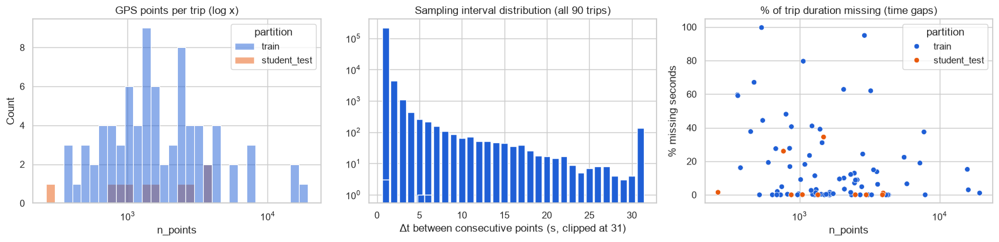

Steps with Δt == 1 s: 96.68%   Δt > 10 s: 617   Δt > 60 s: 70


In [6]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
gps['missing_pct'] = gps.missing_seconds / (gps.duration_s + 1) * 100
sns.histplot(data=gps, x='n_points', hue='partition', palette=PAL, bins=30, log_scale=True, ax=ax[0])
ax[0].set_title('GPS points per trip (log x)')
alldt = np.concatenate([np.diff(t.track.t.to_numpy()) for t in trips])
vc = pd.Series(np.clip(alldt, 0, 31)).value_counts().sort_index()
ax[1].bar(vc.index, vc.values, color=PAL['train']); ax[1].set_yscale('log')
ax[1].set_xlabel('Δt between consecutive points (s, clipped at 31)'); ax[1].set_title('Sampling interval distribution (all 90 trips)')
sns.scatterplot(data=gps, x='n_points', y='missing_pct', hue='partition', palette=PAL, ax=ax[2]); ax[2].set_xscale('log')
ax[2].set_title('% of trip duration missing (time gaps)'); ax[2].set_ylabel('% missing seconds')
savefig('01_points_sampling_missing')
print(f'Steps with Δt == 1 s: {np.mean(alldt == 1):.2%}   Δt > 10 s: {(alldt > 10).sum()}   Δt > 60 s: {(alldt > 60).sum()}')

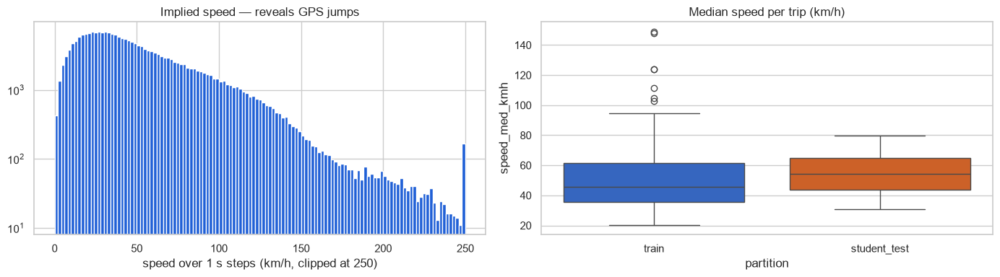

1-s steps implying > 200 km/h: 922 of 219934 (0.4192%)  -> GPS jumps / outliers
Stationary 1-s steps (< 0.5 km/h): 0.02%


In [7]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
allspd = []
for t in trips:
    dt = np.diff(t.track.t.to_numpy()); st = np.linalg.norm(np.diff(t.track_xy, axis=0), axis=1)
    allspd.append(st[dt == 1] * 3.6)  # speed only over clean 1 s steps
allspd = np.concatenate(allspd)
ax[0].hist(np.clip(allspd, 0, 250), bins=125, color=PAL['train']); ax[0].set_yscale('log')
ax[0].set_xlabel('speed over 1 s steps (km/h, clipped at 250)'); ax[0].set_title('Implied speed — reveals GPS jumps')
sns.boxplot(data=gps, x='partition', y='speed_med_kmh', palette=PAL, ax=ax[1]); ax[1].set_title('Median speed per trip (km/h)')
savefig('02_speed')
print(f'1-s steps implying > 200 km/h: {(allspd > 200).sum()} of {len(allspd)} ({(allspd > 200).mean():.4%})  -> GPS jumps / outliers')
print(f'Stationary 1-s steps (< 0.5 km/h): {(allspd < 0.5).mean():.2%}')

## 4. Geographic extent

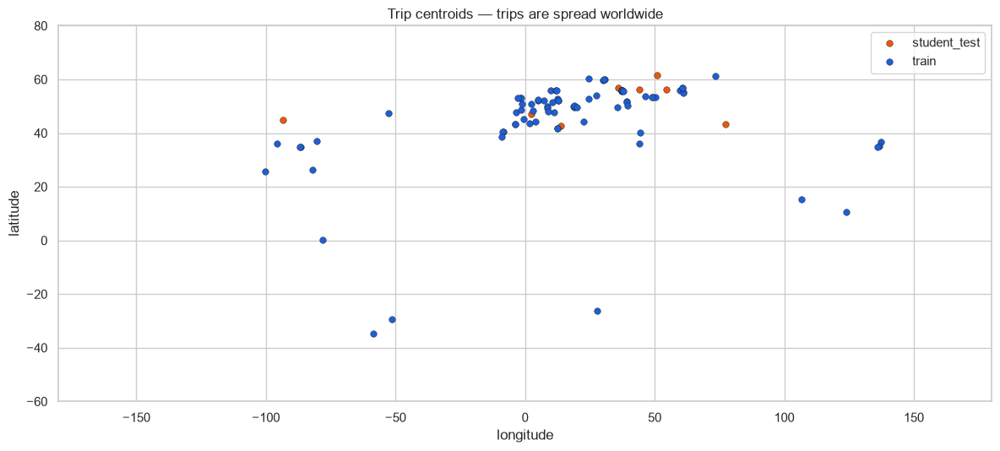

Distinct UTM zones used: 25


partition        student_test  train
bbox_w_km count         10.00  80.00
          mean           9.93  14.09
          std           12.93  16.26
          min            2.19   0.88
          25%            3.21   3.34
          50%            5.29   7.63
          75%           10.39  17.07
          max           45.04  70.92
bbox_h_km count         10.00  80.00
          mean           9.14  11.91
          std            8.01  14.65
          min            1.81   0.87
          25%            3.80   3.30
          50%            5.91   5.31
          75%           11.64  14.01
          max           27.08  75.08

In [8]:
fig, ax = plt.subplots(figsize=(12, 5.5))
for p, g in gps.groupby('partition'):
    ax.scatter(g.lon_c, g.lat_c, s=30, c=PAL[p], label=p, edgecolor='k', lw=0.3)
ax.set_xlim(-180, 180); ax.set_ylim(-60, 80); ax.set_xlabel('longitude'); ax.set_ylabel('latitude')
ax.set_title('Trip centroids — trips are spread worldwide'); ax.legend()
savefig('03_trip_centroids_world')
ext = []
for t in trips:
    xy = t.track_xy; span = xy.max(0) - xy.min(0)
    ext.append(dict(trip=t.trip_id, partition=t.partition, epsg=t.epsg, bbox_w_km=span[0] / 1000, bbox_h_km=span[1] / 1000))
ext = pd.DataFrame(ext)
print('Distinct UTM zones used:', ext.epsg.nunique())
ext.groupby('partition')[['bbox_w_km', 'bbox_h_km']].describe().T.round(2)

In [9]:
world = base_map(location=[30, 10], zoom_start=2)
for p in PARTITIONS:
    fg = folium.FeatureGroup(p)
    for r in gps[gps.partition == p].itertuples():
        folium.CircleMarker([r.lat_c, r.lon_c], radius=5, color=PAL[p], fill=True, fill_opacity=0.9,
                            tooltip=f'{p} {r.trip}: {r.n_points} pts, {r.track_km:.1f} km').add_to(fg)
    fg.add_to(world)
folium.LayerControl(collapsed=False).add_to(world)
world.save(f'{MAPS}/00_world_overview.html'); world

## 5. Road network — size, arc lengths, connectivity

In [10]:
net = []
for t in trips:
    a = t.arcs.to_numpy(); n = len(t.nodes); L = t.arc_length
    G = nx.DiGraph(); G.add_nodes_from(range(n)); G.add_edges_from(map(tuple, a))
    wcc = [len(c) for c in nx.weakly_connected_components(G)]
    scc = [len(c) for c in nx.strongly_connected_components(G)]
    deg = np.bincount(a.ravel(), minlength=n)
    pairs = set(map(tuple, a))
    route_nodes = set(a[t.route].ravel())
    giant_scc = max(nx.strongly_connected_components(G), key=len)
    net.append(dict(partition=t.partition, trip=t.trip_id, n_nodes=n, n_arcs=len(a), arcs_per_node=len(a) / n,
        isolated_nodes=int((deg == 0).sum()), n_wcc=len(wcc), largest_wcc_frac=max(wcc) / n,
        n_scc=len(scc), largest_scc_frac=max(scc) / n,
        route_nodes_in_giant_scc=np.mean([v in giant_scc for v in route_nodes]),
        bidirectional_frac=np.mean([(v, u) in pairs for u, v in pairs]),
        arc_len_med_m=np.median(L), arc_len_p95_m=np.percentile(L, 95), arc_len_max_m=L.max(),
        zero_len_arcs=int((L < 0.01).sum())))
net = pd.DataFrame(net)
net.groupby('partition').describe().T.round(3)

partition            student_test      train
n_nodes       count        10.000     80.000
              mean       9068.900  24168.562
              std        7452.176  32272.296
              min        1770.000    299.000
              25%        4908.000   3487.750
...                           ...        ...
zero_len_arcs min           0.000      0.000
              25%           0.000      0.000
              50%           0.000      0.000
              75%           1.500      2.000
              max           2.000     14.000

[112 rows x 2 columns]

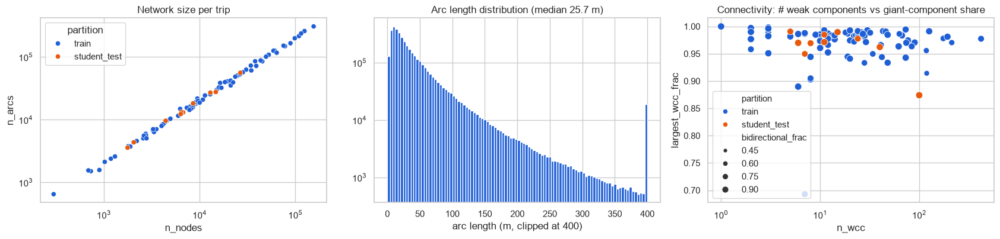

Isolated nodes (all trips): 0
Largest weak component holds 98.0% of nodes (median); min 69.3%
Route nodes inside giant strongly-connected component: median 100.0%, min 46.2%
Two-way (bidirectional) arc share: median 95.1%, min 35.1%


In [11]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.2))
sns.scatterplot(data=net, x='n_nodes', y='n_arcs', hue='partition', palette=PAL, ax=ax[0])
ax[0].set_xscale('log'); ax[0].set_yscale('log'); ax[0].set_title('Network size per trip')
allL = np.concatenate([t.arc_length for t in trips])
ax[1].hist(np.clip(allL, 0, 400), bins=100, color=PAL['train']); ax[1].set_yscale('log')
ax[1].set_xlabel('arc length (m, clipped at 400)'); ax[1].set_title(f'Arc length distribution (median {np.median(allL):.1f} m)')
sns.scatterplot(data=net, x='n_wcc', y='largest_wcc_frac', hue='partition', size='bidirectional_frac', palette=PAL, ax=ax[2])
ax[2].set_xscale('log'); ax[2].set_title('Connectivity: # weak components vs giant-component share')
savefig('04_network_size_connectivity')
print('Isolated nodes (all trips):', net.isolated_nodes.sum())
print(f'Largest weak component holds {net.largest_wcc_frac.median():.1%} of nodes (median); min {net.largest_wcc_frac.min():.1%}')
print(f'Route nodes inside giant strongly-connected component: median {net.route_nodes_in_giant_scc.median():.1%}, min {net.route_nodes_in_giant_scc.min():.1%}')
print(f'Two-way (bidirectional) arc share: median {net.bidirectional_frac.median():.1%}, min {net.bidirectional_frac.min():.1%}')

## 6. Reference route & GPS ↔ road relationship

For each GPS point we measure the perpendicular distance (m) to the **nearest arc on the reference route** and to the
**nearest arc anywhere in the network**. This quantifies GPS noise, informs the candidate-search radius for the
classifier, and exposes trips whose reference route and GPS disagree.

In [12]:
rel = []; route_d_all = {}
for t in trips:
    A, B = t.arc_xy; ru = np.unique(t.route)
    d_route, _ = point_to_segments(t.track_xy, A[ru], B[ru])
    d_any, _ = point_to_segments(t.track_xy, A, B)  # nearest arc anywhere in the network
    route_d_all[t.trip_id] = d_route
    rel.append(dict(partition=t.partition, trip=t.trip_id, n_points=len(t.track), route_arcs=len(t.route),
        unique_route_arcs=len(ru), points_per_route_arc=len(t.track) / len(t.route),
        route_km=t.arc_length[t.route].sum() / 1000, track_km=gps.set_index('trip').loc[t.trip_id, 'track_km'],
        d_route_med=np.median(d_route), d_route_p95=np.percentile(d_route, 95), d_route_max=d_route.max(),
        pct_gt30m=np.mean(d_route > 30) * 100, d_any_med=np.median(d_any)))
rel = pd.DataFrame(rel)
alld = np.concatenate(list(route_d_all.values()))
print('Distance GPS point -> nearest reference-route arc (all points, all trips):')
print(pd.Series(alld).describe(percentiles=[.5, .75, .9, .95, .99]).round(2))
for R in [10, 20, 30, 50, 100]:
    print(f'  share of points within {R:>3} m of the reference route: {np.mean(alld <= R):.2%}')
rel.groupby('partition')[['points_per_route_arc', 'route_km', 'track_km', 'd_route_med', 'd_route_p95']].describe().T.round(2)

Distance GPS point -> nearest reference-route arc (all points, all trips):
count    227577.00
mean         20.18
std          44.49
min           0.00
50%           5.57
75%          10.57
90%          48.69
95%         137.70
99%         200.44
max         569.66
dtype: float64
  share of points within  10 m of the reference route: 73.18%
  share of points within  20 m of the reference route: 86.84%
  share of points within  30 m of the reference route: 88.78%
  share of points within  50 m of the reference route: 90.07%
  share of points within 100 m of the reference route: 91.21%


partition                   student_test   train
points_per_route_arc count         10.00   80.00
                     mean           7.05    8.28
                     std            4.80    9.39
                     min            2.45    1.26
                     25%            3.19    3.32
                     50%            4.63    5.29
                     75%           10.68    8.43
                     max           14.59   56.98
route_km             count         10.00   80.00
                     mean          24.81   27.86
                     std           21.26   25.71
                     min            5.29    5.01
                     25%            9.87    8.93
                     50%           14.76   14.31
                     75%           40.26   39.40
                     max           64.81   94.34
track_km             count         10.00   80.00
                     mean          29.75   37.27
                     std           22.87   34.52
                     min            5.56    6.34
                     25%           12.18   12.80
                     50%           20.96   24.05
                     75%           48.50   48.80
                     max           71.78  169.55
d_route_med          count         10.00   80.00
                     mean           5.04    8.08
                     std            0.92   19.80
                     min            4.18    3.45
                     25%            4.41    4.23
                     50%            4.59    4.50
                     75%            5.74    5.47
                     max            6.84  138.59
d_route_p95          count         10.00   80.00
                     mean          16.31   23.74
                     std            4.25   36.52
                     min           11.69   10.35
                     25%           13.08   12.99
                     50%           15.80   14.21
                     75%           17.98   18.54
                     max           26.16  242.36

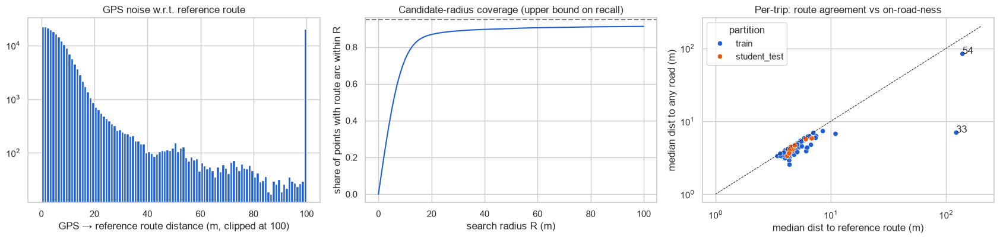

In [13]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.2))
ax[0].hist(np.clip(alld, 0, 100), bins=100, color=PAL['train']); ax[0].set_yscale('log')
ax[0].set_xlabel('GPS → reference route distance (m, clipped at 100)'); ax[0].set_title('GPS noise w.r.t. reference route')
xs = np.arange(0, 101); ax[1].plot(xs, [np.mean(alld <= x) for x in xs], color=PAL['train'])
ax[1].set_xlabel('search radius R (m)'); ax[1].set_ylabel('share of points with route arc within R')
ax[1].set_title('Candidate-radius coverage (upper bound on recall)'); ax[1].axhline(0.95, ls='--', c='grey')
sns.scatterplot(data=rel, x='d_route_med', y='d_any_med', hue='partition', palette=PAL, ax=ax[2])
ax[2].set_xscale('log'); ax[2].set_yscale('log'); ax[2].plot([1, 200], [1, 200], 'k--', lw=0.7)
ax[2].set_xlabel('median dist to reference route (m)'); ax[2].set_ylabel('median dist to any road (m)')
ax[2].set_title('Per-trip: route agreement vs on-road-ness')
for r in rel[rel.d_route_med > 30].itertuples(): ax[2].annotate(r.trip[-2:], (r.d_route_med, r.d_any_med))
savefig('05_gps_route_distance')

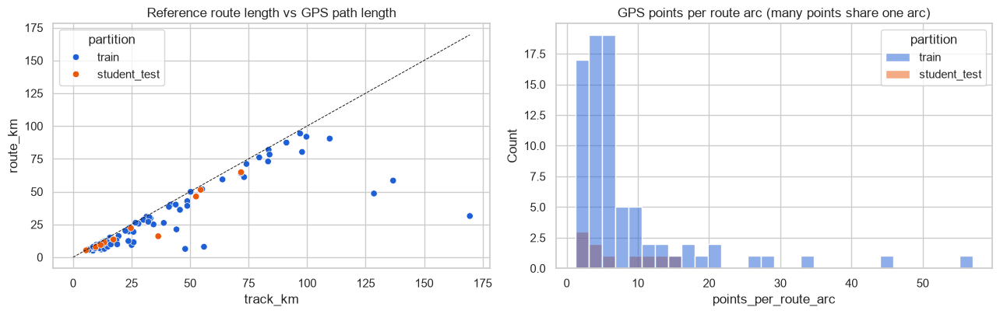

GPS path is longer than route by median factor 1.18 (GPS zig-zag noise + gaps)


In [14]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
sns.scatterplot(data=rel, x='track_km', y='route_km', hue='partition', palette=PAL, ax=ax[0])
m_ = rel[['track_km', 'route_km']].max().max(); ax[0].plot([0, m_], [0, m_], 'k--', lw=0.7)
ax[0].set_title('Reference route length vs GPS path length')
sns.histplot(data=rel, x='points_per_route_arc', hue='partition', palette=PAL, bins=30, ax=ax[1])
ax[1].set_title('GPS points per route arc (many points share one arc)')
savefig('06_route_vs_track')
print(f'GPS path is longer than route by median factor {np.median(rel.track_km / rel.route_km):.2f} (GPS zig-zag noise + gaps)')

## 7. Trajectory plots (projected metres)

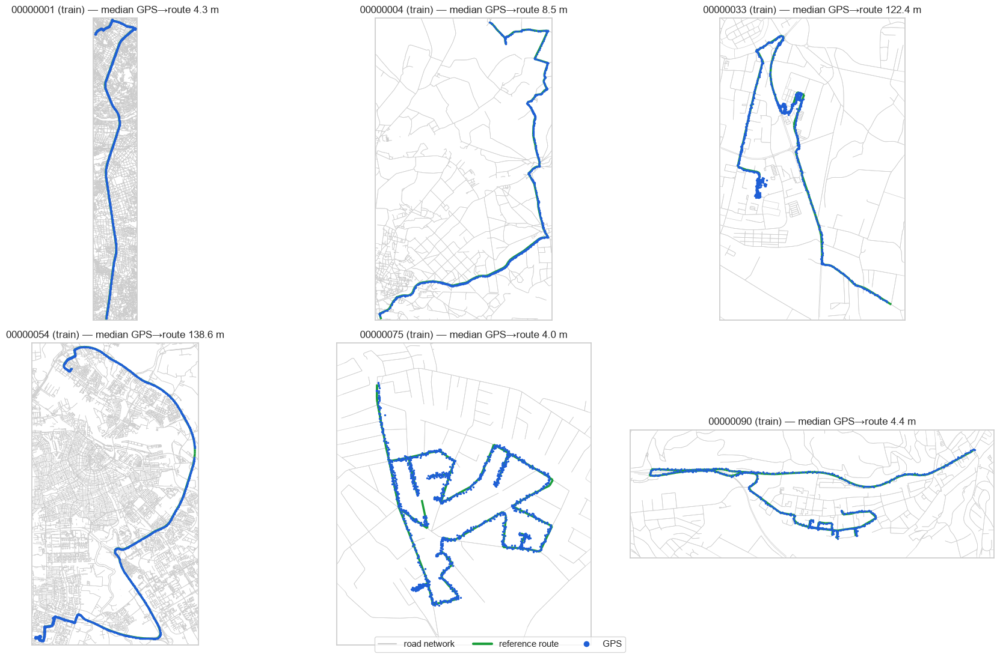

In [15]:
show = ['00000001', '00000004', '00000033', '00000054', '00000075', '00000090']
fig, axes = plt.subplots(2, 3, figsize=(18, 11))
for ax, tid in zip(axes.ravel(), show):
    t = next(x for x in trips if x.trip_id == tid); xy = t.track_xy; A, B = t.arc_xy
    lo, hi = xy.min(0) - 200, xy.max(0) + 200
    near = np.flatnonzero(np.all((A >= lo) & (A <= hi), 1))
    ax.add_collection(LineCollection(np.stack([A[near], B[near]], 1), colors='#cccccc', lw=0.5))
    ax.add_collection(LineCollection(np.stack([A[t.route], B[t.route]], 1), colors=COLORS['reference'], lw=2.5))
    ax.scatter(xy[:, 0], xy[:, 1], s=2, c=COLORS['gps'], zorder=3)
    ax.set_xlim(lo[0], hi[0]); ax.set_ylim(lo[1], hi[1]); ax.set_aspect('equal')
    r = rel.set_index('trip').loc[tid]
    ax.set_title(f'{tid} ({t.partition}) — median GPS→route {r.d_route_med:.1f} m'); ax.set_xticks([]); ax.set_yticks([])
fig.legend(handles=[plt.Line2D([], [], c='#cccccc', label='road network'), plt.Line2D([], [], c=COLORS['reference'], lw=3, label='reference route'),
                    plt.Line2D([], [], c=COLORS['gps'], marker='o', ls='', label='GPS')], loc='lower center', ncol=3)
savefig('07_trajectory_grid')

## 8. Interactive Folium maps

In [16]:
m1 = trip_map(Trip('00000001', 'train')); m1.save(f'{MAPS}/trip_00000001_train.html'); m1

In [17]:
# Anomaly: systematic offset between GPS and map
m2 = trip_map(Trip('00000054', 'train'), gps_every=5); m2.save(f'{MAPS}/trip_00000054_offset.html'); m2

In [18]:
# Anomaly: GPS follows roads that are not on the reference route
m3 = trip_map(Trip('00000033', 'train'), gps_every=2); m3.save(f'{MAPS}/trip_00000033_route_mismatch.html'); m3

In [19]:
# Long time gaps
m4 = trip_map(Trip('00000090', 'train')); m4.save(f'{MAPS}/trip_00000090_gaps.html'); m4

In [20]:
for tid in list_trips('student_test'):
    trip_map(Trip(tid, 'student_test'), gps_every=2).save(f'{MAPS}/trip_{tid}_student_test.html')
print('saved', len(list_trips('student_test')), 'student_test maps to', MAPS)

saved 10 student_test maps to ../outputs/eda/maps


## 9. Anomaly table & saved summaries

In [21]:
summary = (gps.merge(net.drop(columns='partition'), on='trip').merge(rel.drop(columns=['partition', 'n_points', 'track_km']), on='trip')
              .merge(chk.drop(columns='partition'), on='trip'))
flags = pd.DataFrame({'trip': summary.trip, 'partition': summary.partition})
flags['gps_route_offset (median > 30 m)'] = summary.d_route_med > 30
flags['off_road (median dist to any road > 30 m)'] = summary.d_any_med > 30
flags['heavy_tail (p95 > 50 m)'] = summary.d_route_p95 > 50
flags['long_gap (> 300 s)'] = summary.max_gap_s > 300
flags['speed_spikes (> 200 km/h)'] = summary.n_speed_gt200 > 0
flags['route_breaks'] = summary.route_breaks > 0
flags['route_revisits_arcs'] = summary.route_repeated_arcs > 0
flags['t_start != 1'] = summary.t_start != 1
flags['n_flags'] = flags.iloc[:, 2:].sum(1)
summary.to_csv(f'{OUT}/trip_summary.csv', index=False); flags.to_csv(f'{OUT}/trip_flags.csv', index=False)
print('Flag counts:'); print(flags.iloc[:, 2:-1].sum())
flags[flags.n_flags > 0].sort_values('n_flags', ascending=False).head(25)

Flag counts:
gps_route_offset (median > 30 m)              2
off_road (median dist to any road > 30 m)     1
heavy_tail (p95 > 50 m)                       4
long_gap (> 300 s)                           11
speed_spikes (> 200 km/h)                    24
route_breaks                                 11
route_revisits_arcs                          10
t_start != 1                                 16
dtype: int64


,trip,partition,gps_route_offset (median > 30 m),off_road (median dist to any road > 30 m),heavy_tail (p95 > 50 m),long_gap (> 300 s),speed_spikes (> 200 km/h),route_breaks,route_revisits_arcs,t_start != 1,n_flags
26,00000033,train,True,False,True,False,True,True,False,False,4
44,00000054,train,True,True,True,False,False,False,False,False,3
34,00000042,train,False,False,False,True,True,True,False,False,3
55,00000069,train,False,False,False,True,False,True,True,False,3
72,00000090,train,False,False,False,True,False,False,True,True,3
67,00000084,train,False,False,False,True,False,False,True,False,2
64,00000081,train,False,False,False,True,False,False,False,True,2
69,00000086,train,False,False,False,False,False,True,True,False,2
73,00000092,train,False,False,False,False,True,False,True,False,2
18,00000024,train,False,False,False,True,True,False,False,False,2



## 10. Data-quality log, assumptions and decisions

| # | Finding (partition: train + student_test) | Decision / implication |
|---|---|---|
| 1 | 90 trips, all with 4 files; no NaN or invalid coordinates; timestamps strictly increasing | No imputation of values is needed |
| 2 | 96.7% of steps are 1 s; 617 steps > 10 s, 70 steps > 60 s; 23 trips have a gap > 60 s (trip 90: 42 h) | Use Δt as a feature; HMM transitions must scale with Δt; split trips into segments at very long gaps |
| 3 | 16 trips start at t ≠ 1 | Use relative time (t − t₀) |
| 4 | 0.42% of 1-s steps imply > 200 km/h (GPS jumps) | Use speed and jump features; down-weight or flag outlier points |
| 5 | Trips are spread worldwide (25 UTM zones) | Project each trip to its own UTM zone; all distances in metres |
| 6 | Each trip has its own road network (IDs are local); arcs are directed; 95% of arcs are two-way (median) | Build one graph per trip; direction matters for transitions |
| 7 | No isolated nodes, but there are many small components (giant weak component holds a median 98% of nodes) | Transitions between components are impossible; handle "no path" in Viterbi |
| 8 | GPS ≠ route rows (≈ 5 points per route arc) | A label for each point must be derived: project each point onto the reference route in time order |
| 9 | Median GPS→route distance 5.6 m; excluding trips 33 and 54, 95.8% of points are within 20 m and 97.9% within 30 m | Candidate search radius ≈ 30–50 m; report Candidate Miss Rate |
| 10 | Trip 54: GPS shifted about 130 m from the whole map (84 m from any road). Trip 33: GPS lies on roads, but 122 m from the reference route | Labels are unreliable; exclude from training (keep for reporting) |
| 11 | 11 trips have breaks in the reference route chain; 10 revisit arcs (loops); some duplicate or zero-length arcs | The reference route is not perfect ground truth; use time-ordered matching so revisits are handled |
